EDA
ruta de archivos: CMAPSSData

librerias a importar:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path


Carga de archivos:

In [2]:
carpeta = Path("CMAPSSData")
salida = carpeta / "CMAPSS-procesado"
salida.mkdir(exist_ok=True)

cols = (["unidad", "ciclo", "op_setting_1", "op_setting_2", "op_setting_3"] + [f"Sensor_{i}" for i in range(1,22)])

for archivo in carpeta.glob("*_FD00*.txt"):
    df = pd.read_csv(archivo, sep=r"\s+", header=None)
    df = df.dropna(axis=1, how="all") #quita columnas vacias por espacios finales
    if archivo.name.startswith("RUL"):
        df.columns = ["RUL"]
    else:
        df.columns = cols
    df.to_csv(salida / f"{archivo.stem}.csv", index=False)
    print(f"{archivo.name} -> {archivo.stem}.csv {df.shape}")
    

RUL_FD001.txt -> RUL_FD001.csv (100, 1)
RUL_FD002.txt -> RUL_FD002.csv (259, 1)
RUL_FD003.txt -> RUL_FD003.csv (100, 1)
RUL_FD004.txt -> RUL_FD004.csv (248, 1)
test_FD001.txt -> test_FD001.csv (13096, 26)
test_FD002.txt -> test_FD002.csv (33991, 26)
test_FD003.txt -> test_FD003.csv (16596, 26)
test_FD004.txt -> test_FD004.csv (41214, 26)
train_FD001.txt -> train_FD001.csv (20631, 26)
train_FD002.txt -> train_FD002.csv (53759, 26)
train_FD003.txt -> train_FD003.csv (24720, 26)
train_FD004.txt -> train_FD004.csv (61249, 26)


Definimos las columas completas, los 22 sensores y 5 columnas para motor, ciclo y las configuraciones de operacion.

In [3]:
Sensores = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "epr", "Ps30", "phi", "NRf", "NRc", "BPR", "farB", "htBleed", "Nf_dmd", "PCNfR_dmd", "W31", "W32"]
Columnas = ["engine", "cycle", "op_setting_1", "op_setting_2", "op_setting_3"] + Sensores

subsets = ["FD001", "FD002", "FD003", "FD004"]
csv = Path("CMAPSSData") / "CMAPSS-procesado"

In [6]:
def carga_csv(split):
    partes = []
    for fd in subsets:
        df = pd.read_csv(csv / f"{split}_{fd}.csv")
        df.columns = Columnas
        df.insert(0, "subset", fd)
        df.insert(1, "engine_id", fd + "_" + df["engine"].astype(str))
        if split == "test":
            rul = pd.read_csv(csv / f"RUL_{fd}.csv")["RUL"]
            df["RUL_final"] = df["engine"].map(dict(zip(range(1, len(rul) + 1), rul)))
        else:
            df["RUL"] = df.groupby("engine")["cycle"].transform("max") - df["cycle"]
        partes.append(df)
    return pd.concat(partes, ignore_index=True)

train = carga_csv("train")
test = carga_csv("test")
print(train.shape, test.shape)

(160359, 29) (104897, 29)


EDA para subset de CMAPSS

Para el dataframe train, tenemos un total de 160,359 filas con 29 columnas. Aqui hay un conjuntos de los motores unicamente para test.

| subset | Filas en train | Motores|
|---|---|---|
| FD001 | 20,631 | 100 |
| FD002 | 53,759 | 260 | 
| FD003 | 24,720 | 100 |
| FD004 | 61,249 | 249 | 


In [11]:
train

,subset,engine_id,engine,cycle,op_setting_1,op_setting_2,op_setting_3,T2,T24,T30,...,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32,RUL
0,FD001,FD001_1,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,FD001,FD001_1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,FD001,FD001_1,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,FD001,FD001_1,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,FD001,FD001_1,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160354,FD004,FD004_249,249,251,9.9998,0.2500,100.0,489.05,605.33,1516.36,...,2388.73,8185.69,8.4541,0.03,372,2319,100.0,29.11,17.5234,4
160355,FD004,FD004_249,249,252,0.0028,0.0015,100.0,518.67,643.42,1598.92,...,2388.46,8185.47,8.2221,0.03,396,2388,100.0,39.38,23.7151,3
160356,FD004,FD004_249,249,253,0.0029,0.0000,100.0,518.67,643.68,1607.72,...,2388.48,8193.94,8.2525,0.03,395,2388,100.0,39.78,23.8270,2
160357,FD004,FD004_249,249,254,35.0046,0.8400,100.0,449.44,555.77,1381.29,...,2388.83,8125.64,9.0515,0.02,337,2223,100.0,15.26,9.0774,1


In [12]:
train.shape

(160359, 29)

In [14]:
df.loc[0]

unidad             1.0000
ciclo              1.0000
op_setting_1      42.0049
op_setting_2       0.8400
op_setting_3     100.0000
Sensor_1         445.0000
Sensor_2         549.6800
Sensor_3        1343.4300
Sensor_4        1112.9300
Sensor_5           3.9100
Sensor_6           5.7000
Sensor_7         137.3600
Sensor_8        2211.8600
Sensor_9        8311.3200
Sensor_10          1.0100
Sensor_11         41.6900
Sensor_12        129.7800
Sensor_13       2387.9900
Sensor_14       8074.8300
Sensor_15          9.3335
Sensor_16          0.0200
Sensor_17        330.0000
Sensor_18       2212.0000
Sensor_19        100.0000
Sensor_20         10.6200
Sensor_21          6.3670
Name: 0, dtype: float64

In [15]:
train.dtypes

subset              str
engine_id           str
engine            int64
cycle             int64
op_setting_1    float64
op_setting_2    float64
op_setting_3    float64
T2              float64
T24             float64
T30             float64
T50             float64
P2              float64
P15             float64
P30             float64
Nf              float64
Nc              float64
epr             float64
Ps30            float64
phi             float64
NRf             float64
NRc             float64
BPR             float64
farB            float64
htBleed           int64
Nf_dmd            int64
PCNfR_dmd       float64
W31             float64
W32             float64
RUL               int64
dtype: object

---

#### Nulos y duplicados

In [21]:
print("Nulos:", train.isna().sum().sum())
print("Duplicados (motor, ciclo):", train.duplicated(["engine_id", "cycle"]).sum())

Nulos: 0
Duplicados (motor, ciclo): 0


In [17]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 160359 entries, 0 to 160358
Data columns (total 29 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   subset        160359 non-null  str    
 1   engine_id     160359 non-null  str    
 2   engine        160359 non-null  int64  
 3   cycle         160359 non-null  int64  
 4   op_setting_1  160359 non-null  float64
 5   op_setting_2  160359 non-null  float64
 6   op_setting_3  160359 non-null  float64
 7   T2            160359 non-null  float64
 8   T24           160359 non-null  float64
 9   T30           160359 non-null  float64
 10  T50           160359 non-null  float64
 11  P2            160359 non-null  float64
 12  P15           160359 non-null  float64
 13  P30           160359 non-null  float64
 14  Nf            160359 non-null  float64
 15  Nc            160359 non-null  float64
 16  epr           160359 non-null  float64
 17  Ps30          160359 non-null  float64
 18  phi           1

---

#### Estadisticas descriptivas

In [22]:
descriptivas = train[Sensores + ["RUL"]].describe().T
descriptivas["asimetria"] = train[Sensores + ["RUL"]].skew()
descriptivas[["mean", "std", "min", "50%", "max", "asimetria"]].round(2)

,mean,std,min,50%,max,asimetria
T2,485.84,30.42,445.00,489.05,518.67,-0.18
T24,597.36,42.48,535.48,605.93,645.11,-0.19
T30,1467.04,118.18,1242.67,1492.81,1616.91,-0.35
T50,1260.96,136.30,1023.77,1271.74,1441.49,-0.19
P2,9.89,4.27,3.91,9.35,14.62,-0.12
P15,14.42,6.44,5.67,13.66,21.61,-0.07
P30,359.73,174.13,136.17,341.69,570.81,-0.04
Nf,2273.83,142.43,1914.72,2319.37,2388.64,-1.51
Nc,8677.55,374.66,7984.51,8764.20,9244.59,-0.37
epr,1.15,0.14,0.93,1.09,1.32,-0.13


---

#### Sensores y constantes por subset

Vamos a calcular la desviacion de cada sensor dentro de cada subset. Los que dan casi 0 no aportan informacion para predecir y se pueden descartar del modelo de ese subset.

In [23]:
std_sensores = train.groupby("subset")[Sensores].std().T.round(4)
constantes = {fd: std_sensores.index[std_sensores[fd] < 1e-3].tolist() for fd in subsets}
print(constantes)

std_sensores

{'FD001': ['T2', 'P2', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd'], 'FD002': [], 'FD003': ['T2', 'P2', 'farB', 'Nf_dmd', 'PCNfR_dmd'], 'FD004': []}


subset,FD001,FD002,FD003,FD004
T2,0.0000,26.3897,0.0000,26.4368
T24,0.5001,37.2894,0.5230,37.3426
T30,6.1311,105.9463,6.8104,106.1676
T50,9.0006,119.1234,9.7732,119.3276
P2,0.0000,3.6138,0.0000,3.6229
P15,0.0014,5.4318,0.0181,5.4440
P30,0.8851,146.0053,3.4373,146.8802
Nf,0.0710,145.2098,0.1583,145.3482
Nc,22.0829,335.8120,19.9803,336.9275
epr,0.0000,0.1275,0.0035,0.1277


---

#### Ciclos hasta la falla del motor

        count   mean   std    min    25%    50%    75%    max
subset                                                       
FD001   100.0  206.3  46.3  128.0  177.0  199.0  229.2  362.0
FD002   260.0  206.8  46.8  128.0  174.0  199.0  230.2  378.0
FD003   100.0  247.2  86.5  145.0  189.8  220.5  279.8  525.0
FD004   249.0  246.0  73.1  128.0  190.0  234.0  290.0  543.0


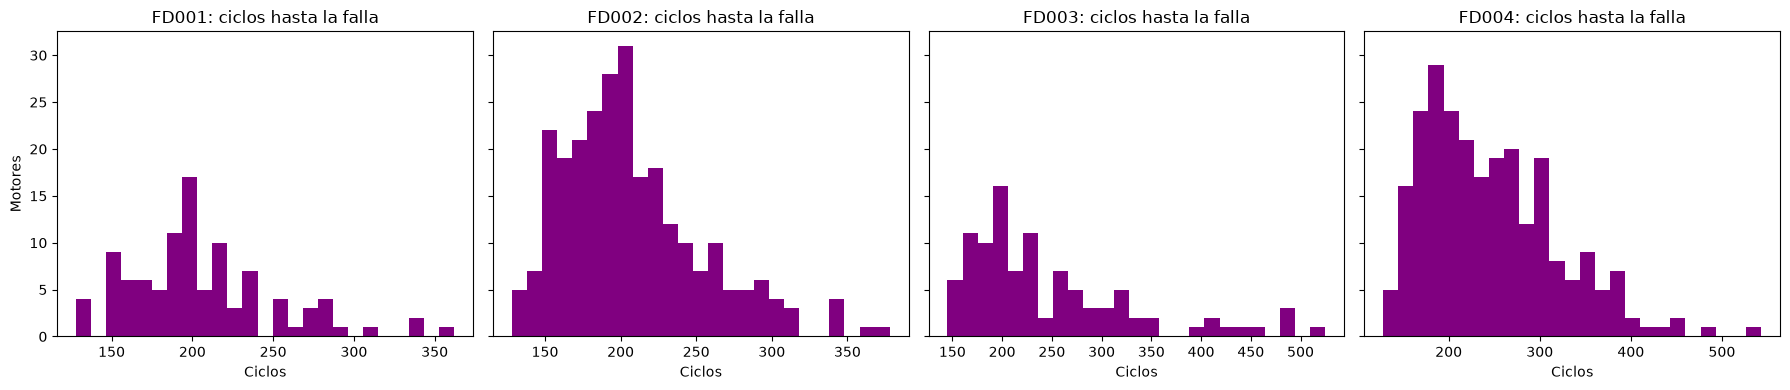

In [25]:
vida = train.groupby(["subset","engine_id"])["cycle"].max().reset_index(name="ciclos_falla")
print(vida.groupby("subset")["ciclos_falla"].describe().round(1))

fig, ejes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, fd in zip(ejes, subsets):
    ax.hist(vida.loc[vida["subset"] == fd, "ciclos_falla"], bins=25, color="purple")
    ax.set_title(f"{fd}: ciclos hasta la falla")
    ax.set_xlabel("Ciclos")
ejes[0].set_ylabel("Motores")
plt.tight_layout()
plt.show()

---

#### Correlacion de cada sensor con el RUL

Ahora se calculara la correlacion de pearson para los sensores del subset. Observaremos que habra valores en donde su desviacion es σ = 0. Si observamos la formula:

$$r = \frac{\text{cov}(\text{sensor}, \text{RUL})}{\sigma_{\text{sensor}} \cdot \sigma_{\text{RUL}}}$$

Cuando un sensor no tiene cambios y su desviacion es igual a 0, la division no esta definida y pandas devuelve un valor NaN. Esto quiere decir que si un sensor nunca cambia no puede moverse con el RUL.

In [27]:
corr_rul = (train.groupby("subset").apply(lambda d: d[Sensores].corrwith(d["RUL"])).T.round(2))

corr_rul

subset,FD001,FD002,FD003,FD004
T2,NaN,-0.00,NaN,0.00
T24,-0.61,-0.00,-0.59,-0.00
T30,-0.58,-0.03,-0.62,-0.03
T50,-0.68,-0.04,-0.66,-0.05
P2,0.00,-0.00,0.00,0.00
P15,-0.13,-0.00,-0.22,0.00
P30,0.66,0.00,-0.32,-0.00
Nf,-0.56,0.00,-0.66,0.00
Nc,-0.39,-0.02,-0.55,-0.02
epr,NaN,0.00,-0.36,-0.01


Correlacion acomodada para cada subset de motores

In [33]:
corr_rul["FD001"].sort_values(key=abs, ascending=False)

Ps30        -0.70
T50         -0.68
phi          0.67
P30          0.66
BPR         -0.64
W32          0.64
W31          0.63
T24         -0.61
htBleed     -0.61
T30         -0.58
NRf         -0.56
Nf          -0.56
Nc          -0.39
NRc         -0.31
P15         -0.13
P2           0.00
farB         0.00
T2            NaN
epr           NaN
Nf_dmd        NaN
PCNfR_dmd     NaN
Name: FD001, dtype: float64

In [34]:
for fd in subsets:
    orden = corr_rul[fd].sort_values(key=abs, ascending=False)
    print(f"\n=== {fd} ===")
    print(orden.to_string())



=== FD001 ===
Ps30        -0.70
T50         -0.68
phi          0.67
P30          0.66
BPR         -0.64
W32          0.64
W31          0.63
T24         -0.61
htBleed     -0.61
T30         -0.58
NRf         -0.56
Nf          -0.56
Nc          -0.39
NRc         -0.31
P15         -0.13
P2           0.00
farB         0.00
T2            NaN
epr           NaN
Nf_dmd        NaN
PCNfR_dmd     NaN

=== FD002 ===
farB        -0.07
Ps30        -0.05
NRc         -0.04
BPR         -0.04
T50         -0.04
htBleed     -0.03
T30         -0.03
Nc          -0.02
NRf          0.01
W32          0.01
W31          0.01
PCNfR_dmd    0.01
T2          -0.00
P2          -0.00
T24         -0.00
phi          0.00
Nf           0.00
P15         -0.00
epr          0.00
P30          0.00
Nf_dmd       0.00

=== FD003 ===
Ps30        -0.69
T50         -0.66
Nf          -0.66
NRf         -0.66
htBleed     -0.65
T30         -0.62
T24         -0.59
Nc          -0.55
NRc         -0.48
epr         -0.36
phi         -0.33
P

Para el primer subset FD001, podemos notar que hay sensores que estan fuertemente relacionados con la RUL pero por si solos no aportarian informacion para poder describir al RUL.

| Fuerza | Sensores (r con el RUL) | Interpretacion |
|---|---|---|
| Moderada-fuerte (0.6 - 0.7) | Ps30 -0.70, T50 -0.68, phi +0.67, P30 +0.66, BPR -0.64, W32 +0.64, W31 +0.63, T24 -0.61, htBleed -0.61 | Siguen claramente la degradacion. Son los mejores candidatos para el modelo. |
| Moderada (0.5 - 0.6) | T30 -0.58, Nf -0.56, NRf -0.56 | Tambien fuerte |
| Debil (0.3 - 0.4) | Nc -0.39, NRc -0.31 | Aportan poco por si solos. | 
| Casi nula (<0.15) | P15 -0.13, P2 0.00, farB 0.00 | No siguen la degradacion |
| Sin Valor | T2, epr, Nf_dmd, PCNfR_dmd | Constantes en FD001; se descartan |

Para P2 y farB salen $\approx$ 0 en vez de NaN porque varian en decimales, esto no afecta la desicion de no incluirlos para analisis.

Que pasa con el motor al acercarse a la falla:

- Con las lectucars **negativas** el sensor sube: las temperaturas (`T24`, `T30`, `T50`), la presion estatica `Ps30`, el sangrado `htBleed`, la relacion de bypass `BPR` y las velocidades del ventilador (fan: `Nf`, `NRf`). El motor trabaja mas caliente y con mas esfuerzo para entregar el mismo empuje.

- Con las lecturas **positivas** el sensor baja: para `P30`, `phi`, `W31`, `W32`. Todos dependen del flujo que entrega el HPC, que es el componente que se degrada en FD001.

*El compresor de alta pierde eficiencia y el resto del motor compensa calentándose y esforzándose más.*



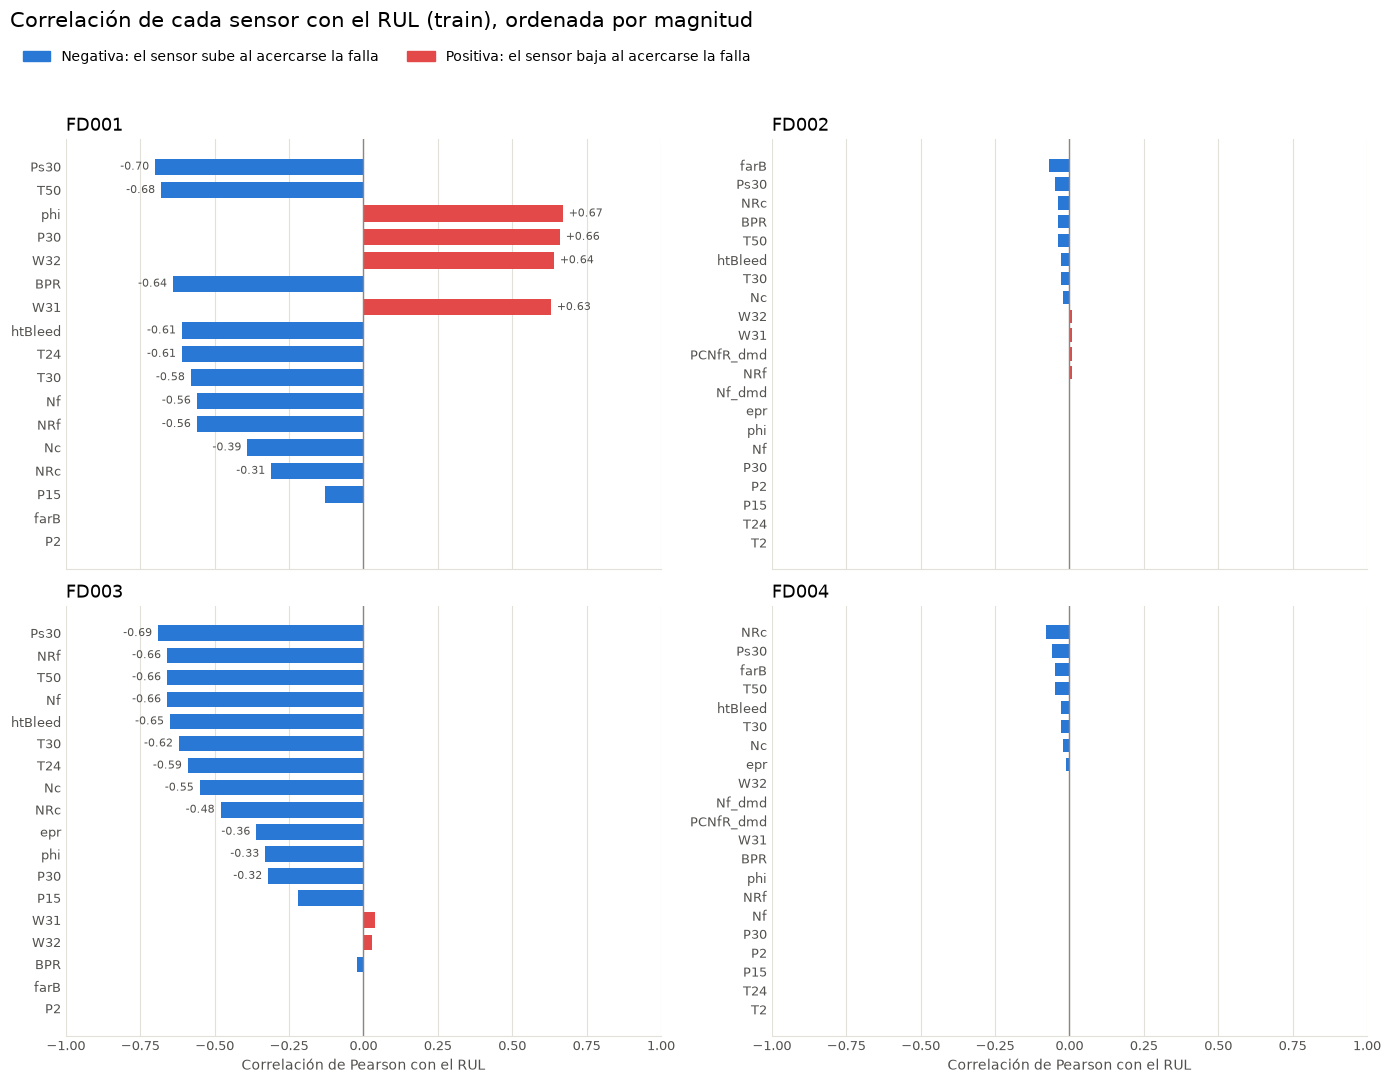

In [ ]:
from matplotlib.patches import Patch

AZUL, ROJO = "#2a78d6", "#e34948"
TEXTO, GRIS, REJILLA = "#52514e", "#898781", "#e1e0d9"

fig, ejes = plt.subplots(2, 2, figsize=(14, 11), sharex=True)
for ax, fd in zip(ejes.ravel(), subsets):
    orden = corr_rul[fd].dropna().sort_values(key=abs)   # barh dibuja de abajo hacia arriba: el mayor queda arriba
    colores = [AZUL if v < 0 else ROJO for v in orden] # type: ignore
    ax.barh(orden.index, orden.values, color=colores, height=0.7)
    ax.axvline(0, color=GRIS, lw=1)

    # etiqueta solo las correlaciones relevantes (|r| >= 0.3)
    for i, v in enumerate(orden.values):
        if abs(v) >= 0.3:
            ax.text(v + (0.02 if v > 0 else -0.02), i, f"{v:+.2f}", va="center",
                    ha="left" if v > 0 else "right", fontsize=8, color=TEXTO)

    ax.set_title(fd, loc="left", fontsize=13)
    ax.set_xlim(-1, 1)
    ax.grid(axis="x", color=REJILLA, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXTO, labelsize=9, length=0)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(REJILLA)

for ax in ejes[1]:
    ax.set_xlabel("Correlación de Pearson con el RUL", color=TEXTO)

fig.legend(handles=[Patch(color=AZUL, label="Negativa: el sensor sube al acercarse la falla"),
                    Patch(color=ROJO, label="Positiva: el sensor baja al acercarse la falla")],
           loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=2, frameon=False, fontsize=10)
fig.suptitle("Correlación de cada sensor con el RUL (train), ordenada por magnitud",
             x=0.01, ha="left", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.93]) # type: ignore
plt.savefig("Images/Correlacion sensores vs RUL.png", dpi=300, bbox_inches="tight")
plt.show()

Las correlaciones se calcularon con todos los motores del subset juntos. Calculadas motor por motor son más fuertes ($\approx$ 0.8 para `Ps30`, `T50`, `phi` y `P30`), lo que indica que parte de la variación se debe a diferencias entre motores (desgaste inicial distinto) y no al sensor.

In [37]:
fd001 = train[train["subset"] == "FD001"]

corr_por_motor = fd001.groupby("engine").apply(lambda d: d[Sensores].corrwith(d["RUL"]))

resumen = pd.DataFrame({
    "global": fd001[Sensores].corrwith(fd001["RUL"]),
    "media_motor": corr_por_motor.mean(),
    "min": corr_por_motor.min(),
    "max": corr_por_motor.max(),
}).dropna().sort_values("media_motor", key=abs, ascending=False).round(2)
resumen

,global,media_motor,min,max
Ps30,-0.70,-0.81,-0.87,-0.68
phi,0.67,0.79,0.64,0.86
T50,-0.68,-0.78,-0.84,-0.64
P30,0.66,0.76,0.59,0.86
BPR,-0.64,-0.72,-0.81,-0.62
W32,0.64,0.72,0.58,0.80
W31,0.63,0.71,0.60,0.82
NRf,-0.56,-0.69,-0.86,-0.13
Nf,-0.56,-0.68,-0.86,-0.15
T24,-0.61,-0.68,-0.79,-0.50


---

#### Condiciones de operacion

Ahora obtendremos las condiciones de operacion para cada subset de prubas. Cada condicion corresponde a **Altitud**, **Mach** y **Acelerador (TRA)**.



In [39]:
train["condicion"] = (train["op_setting_1"].round(0).astype(int).astype(str) + "__" +
                      train["op_setting_2"].round(2).add(0).astype(str) + "__" +
                      train["op_setting_3"].astype(int).astype(str))
pd.crosstab(train["condicion"], train["subset"])

subset,FD001,FD002,FD003,FD004
condicion,,,,
0__0.0__100,20631,8044,24720,9238
10__0.25__100,0,8096,0,9224
20__0.7__100,0,8122,0,9091
25__0.62__60,0,8002,0,9139
35__0.84__100,0,8037,0,9162
42__0.84__100,0,13458,0,15395
